<a href="https://colab.research.google.com/github/maulidyaafriani/Pembelajaran-Mesin-2026/blob/main/TG14_CNN_JST_244107020059_MAULIDYA_AFRIANI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS14 - Praktikum 1: Klasifikasi Risiko Diabetes (GlucoSafe) dengan Neural Network
**Membangun & Ekspor Model**

Nama: Maulidya Afriani  |  NIM: 244107020059

Notebook ini adalah versi project GlucoSafe dari Praktikum 1 (Day vs Night). Alurnya sama persis: import, load dataset, preprocessing, normalisasi, split, bangun model, training, evaluasi, lalu ekspor model `.h5` dan scaler `.pkl` untuk deployment (JS15).

**Perbedaan dengan studi kasus Day vs Night**

| Day vs Night | GlucoSafe |
|---|---|
| Data citra (jpg) | Data tabular CSV (BRFSS 2015, 21 fitur) |
| Ekstraksi fitur HOG | Pemisahan fitur & target (tidak perlu HOG) |
| Biner (sigmoid, 1 neuron) | 3 kelas: 0 = Tidak Diabetes, 1 = Prediabetes, 2 = Diabetes (softmax, 3 neuron) |
| `binary_crossentropy` | `sparse_categorical_crossentropy` |

## Langkah 1: Import Library dan Mount Google Drive

In [1]:
from pathlib import Path
import json, pickle, shutil, sys, platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

from google.colab import drive
drive.mount('/content/drive')

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__, "| scikit-learn:", sklearn.__version__)

Mounted at /content/drive
TensorFlow: 2.21.0 | scikit-learn: 1.6.1


## Langkah 2: Load Dataset

Dataset: `diabetes_012_health_indicators_BRFSS2015.csv`.
Catatan: sesuaikan `DATA_DIR` dengan lokasi folder dataset di Google Drive-mu.

In [2]:
DATA_DIR = Path("/content/drive/MyDrive/glucosafe/Datasate")
CSV_NAME = "diabetes_012_health_indicators_BRFSS2015.csv"

csv_path = DATA_DIR / CSV_NAME
if not csv_path.exists():
    # Cari otomatis kalau nama file / subfolder sedikit berbeda
    candidates = list(DATA_DIR.rglob("*.csv"))
    if not candidates:
        raise FileNotFoundError(f"Tidak ada file CSV di {DATA_DIR}. Cek lagi path-nya.")
    csv_path = candidates[0]
    print("File default tidak ditemukan, memakai:", csv_path)

df = pd.read_csv(csv_path)
print("Ukuran data:", df.shape)
display(df.head())

print("\nDistribusi kelas target (Diabetes_012):")
print(df["Diabetes_012"].value_counts().sort_index())
print("\nMissing value total:", df.isna().sum().sum())
print("Baris duplikat:", df.duplicated().sum())

File default tidak ditemukan, memakai: /content/drive/MyDrive/glucosafe/Datasate/diabetes_012_health_indicators_BRFSS2015.csv (5)/diabetes_012_health_indicators_BRFSS2015.csv
Ukuran data: (10000, 23)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Cluster,Diabetes_012
0,-0.866785,-0.858182,0.196922,-1.117071,-0.892119,-0.205637,-0.322458,-1.762814,0.759375,0.482087,...,0.457294,-0.024926,0.316350,-0.449718,-0.887021,-0.337933,-1.065595,-1.957312,0,0.0
1,1.153688,1.165254,0.196922,-0.057858,-0.892119,-0.205637,-0.322458,0.567275,0.759375,0.482087,...,0.457294,-0.429630,-0.486592,-0.449718,-0.887021,1.626566,0.963272,-0.026012,0,0.0
2,-0.866785,-0.858182,0.196922,-0.663122,-0.892119,-0.205637,-0.322458,0.567275,0.759375,0.482087,...,-1.414532,-0.429630,-0.486592,-0.449718,1.127369,-2.302431,-1.065595,0.456813,0,0.0
3,-0.866785,-0.858182,0.196922,-0.209174,1.120927,-0.205637,-0.322458,0.567275,-1.316872,0.482087,...,-0.478619,-0.024926,-0.486592,-0.449718,1.127369,-1.975015,-1.065595,0.456813,0,0.0
4,-0.866785,1.165254,0.196922,0.396091,1.120927,-0.205637,-0.322458,-1.762814,0.759375,0.482087,...,1.393207,3.212703,2.610472,2.223615,-0.887021,-0.010516,-2.080028,-1.957312,-1,0.0



Distribusi kelas target (Diabetes_012):
Diabetes_012
0.0    8460
1.0     180
2.0    1360
Name: count, dtype: int64

Missing value total: 0
Baris duplikat: 143


## Langkah 3: Preprocessing

Hasil pengecekan pada dataset ini:

1. **Fitur sudah berupa z-score** (sudah dinormalisasi, nilainya negatif/desimal), bukan nilai asli. Padahal aplikasi deployment nanti menerima input asli (misal BMI 27 atau usia kategori 6). Karena itu nilai asli dikembalikan dulu. Cara pengembaliannya: untuk kolom bilangan bulat, selisih antar nilai z-score unik terkecil = 1/std, lalu rata-rata dihitung dari nilai minimum aslinya (biner = 0, BMI = 12, GenHlth/Age/Education/Income = 1, MentHlth/PhysHlth = 0). Hasilnya divalidasi: semua nilai kembali menjadi bilangan bulat.
2. Kolom **`Cluster`** adalah label hasil clustering (turunan dari fitur lain, bukan data survei, dan tidak akan ada saat pengguna mengisi form), jadi **di-drop**.
3. Baris duplikat dihapus agar tidak bocor antara data train dan test.

In [3]:
TARGET = "Diabetes_012"
LABELS = {0: "Tidak Diabetes", 1: "Prediabetes", 2: "Diabetes"}

# (a) Cek: apakah fitur memang sudah z-score?
feat_cols = [c for c in df.columns if c not in ("Cluster", TARGET)]
print("Rata-rata kolom (harusnya ~0):", round(float(df[feat_cols].mean().abs().max()), 4))
print("Std kolom (harusnya ~1):      ", df[feat_cols].std().round(3).unique())

# (b) Drop kolom Cluster
df = df.drop(columns=["Cluster"])
FEATURES = [c for c in df.columns if c != TARGET]

# (c) Kembalikan ke nilai asli
RAW_MIN = {c: 0 for c in FEATURES}
RAW_MIN.update({"BMI": 12, "GenHlth": 1, "Age": 1, "Education": 1, "Income": 1})

def restore_raw(col):
    uniq = np.sort(col.unique())
    std = 1 / np.diff(uniq).min()
    mean = RAW_MIN[col.name] - uniq[0] * std
    return col * std + mean

X_raw = df[FEATURES].apply(restore_raw)
assert np.allclose(X_raw, X_raw.round(), atol=1e-6), "Rekonstruksi gagal: nilai tidak bulat"
X_raw = X_raw.round().astype(int)

data = X_raw.copy()
data[TARGET] = df[TARGET].astype(int)

# (d) Hapus duplikat
before = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print(f"\nBaris sebelum: {before} -> sesudah hapus duplikat: {len(data)}")

display(data.describe().T[["min", "max", "mean"]].round(2))

Rata-rata kolom (harusnya ~0): 0.015
Std kolom (harusnya ~1):       [1.    0.994 0.981 1.012 1.001 0.996 0.998 1.005 1.008 1.015 1.002 0.995
 1.007 0.997]

Baris sebelum: 10000 -> sesudah hapus duplikat: 9857


,min,max,mean
HighBP,0.0,1.0,0.43
HighChol,0.0,1.0,0.43
CholCheck,0.0,1.0,0.96
BMI,12.0,95.0,28.50
Smoker,0.0,1.0,0.45
Stroke,0.0,1.0,0.04
HeartDiseaseorAttack,0.0,1.0,0.10
PhysActivity,0.0,1.0,0.76
Fruits,0.0,1.0,0.63
Veggies,0.0,1.0,0.81


## Langkah 4: Pemisahan Fitur & Target

Pada Day vs Night, langkah ini berupa ekstraksi fitur HOG. Untuk data tabular, fiturnya sudah siap dipakai, sehingga cukup dipisahkan dari target. Distribusi kelas juga divisualisasikan karena sangat tidak seimbang.

Bentuk X: (9857, 21) | Bentuk y: (9857,)


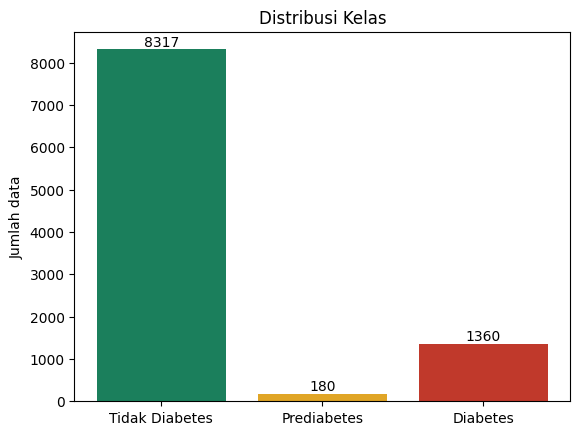

Akurasi baseline (selalu menebak kelas mayoritas): 0.8438


In [4]:
X = data[FEATURES].values.astype("float32")
y = data[TARGET].values.astype("int32")

print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)

counts = pd.Series(y).value_counts().sort_index()
plt.bar([LABELS[i] for i in counts.index], counts.values, color=["#1b7f5c", "#e0a526", "#c0392b"])
for i, v in enumerate(counts.values):
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.title("Distribusi Kelas")
plt.ylabel("Jumlah data")
plt.show()

print(f"Akurasi baseline (selalu menebak kelas mayoritas): {counts.max() / counts.sum():.4f}")

## Langkah 5: Split Train/Test dan Normalisasi Fitur

Data dibagi 80% train dan 20% test dengan `stratify` agar proporsi kelas terjaga. `StandardScaler` hanya di-`fit` pada data train agar tidak terjadi data leakage.

In [6]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

print("Train:", X_train_scaled.shape, "| Test:", X_test_scaled.shape)

Train: (7885, 21) | Test: (1972, 21)


## Langkah 6: Split Data Training & Validation

In [8]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train
)
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test_scaled.shape)

Train: (6308, 21) | Val: (1577, 21) | Test: (1972, 21)


## Langkah 7: Konversi Label ke Numpy Array dan Class Weight

Karena kelas sangat tidak seimbang (Prediabetes sangat sedikit), dipakai *class weight* agar kelas minoritas ikut diperhatikan model. Bobot memakai akar dari bobot "balanced" supaya tidak terlalu ekstrem.

In [9]:
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

cnt = np.bincount(y_train)
class_weight = {i: float((len(y_train) / (len(cnt) * cnt[i])) ** 0.5) for i in range(len(cnt))}
print("Jumlah per kelas (train):", dict(enumerate(cnt)))
print("Class weight:", {k: round(v, 3) for k, v in class_weight.items()})

Jumlah per kelas (train): {0: np.int64(5322), 1: np.int64(115), 2: np.int64(871)}
Class weight: {0: 0.629, 1: 4.276, 2: 1.554}


## Langkah 8: Membangun Arsitektur Model Neural Network

- Input: 21 fitur
- Hidden layer 1: 128 neuron, ReLU (+ Dropout 0.3)
- Hidden layer 2: 64 neuron, ReLU (+ Dropout 0.2)
- Output: 3 neuron, **Softmax** (3 kelas)
- Loss: `sparse_categorical_crossentropy` (label berupa bilangan bulat 0/1/2)

In [10]:
input_dim = X_train.shape[1]
num_classes = len(LABELS)

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,267 (44.01 KB)

 Trainable params: 11,267 (44.01 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 9: Training Model

Maksimal 30 epoch dengan *EarlyStopping* (berhenti jika `val_loss` tidak membaik selama 5 epoch, lalu memakai bobot terbaik).

In [11]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    class_weight=class_weight,
    callbacks=[early_stop],
)

Epoch 1/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7846 - loss: 0.6711 - val_accuracy: 0.8009 - val_loss: 0.5278
Epoch 2/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8069 - loss: 0.5952 - val_accuracy: 0.7901 - val_loss: 0.5206
Epoch 3/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8098 - loss: 0.5800 - val_accuracy: 0.7939 - val_loss: 0.5175
Epoch 4/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8074 - loss: 0.5772 - val_accuracy: 0.8003 - val_loss: 0.5105
Epoch 5/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8112 - loss: 0.5692 - val_accuracy: 0.7901 - val_loss: 0.5170
Epoch 6/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8134 - loss: 0.5562 - val_accuracy: 0.7958 - val_loss: 0.5111
Epoch 7/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8153 - loss: 0.5599 - val_accuracy: 0.7971 - val_loss: 0.5127
Epoch 8/30
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8099 - loss: 0.5530 - val_accuracy: 0.8009 - val_loss:

## Langkah 10: Evaluasi Model pada Data Testing

In [12]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print("Loss Test    :", round(test_loss, 4))
print("Akurasi Test :", round(test_acc, 4))
print("Baseline mayoritas:", round(np.bincount(y_test).max() / len(y_test), 4))

Loss Test    : 0.4989
Akurasi Test : 0.8093
Baseline mayoritas: 0.8438


## Langkah 11: Prediksi, Classification Report, Confusion Matrix, dan Visualisasi



                precision    recall  f1-score   support

Tidak Diabetes       0.91      0.87      0.89      1664
   Prediabetes       0.00      0.00      0.00        36
      Diabetes       0.40      0.57      0.47       272

      accuracy                           0.81      1972
     macro avg       0.44      0.48      0.45      1972
  weighted avg       0.82      0.81      0.81      1972

[[1442    4  218]
 [  26    0   10]
 [ 118    0  154]]


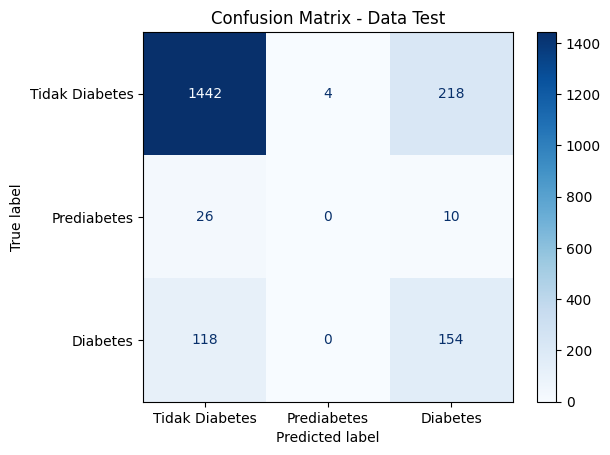

In [13]:
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

target_names = [LABELS[i] for i in range(num_classes)]
print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Data Test")
plt.show()

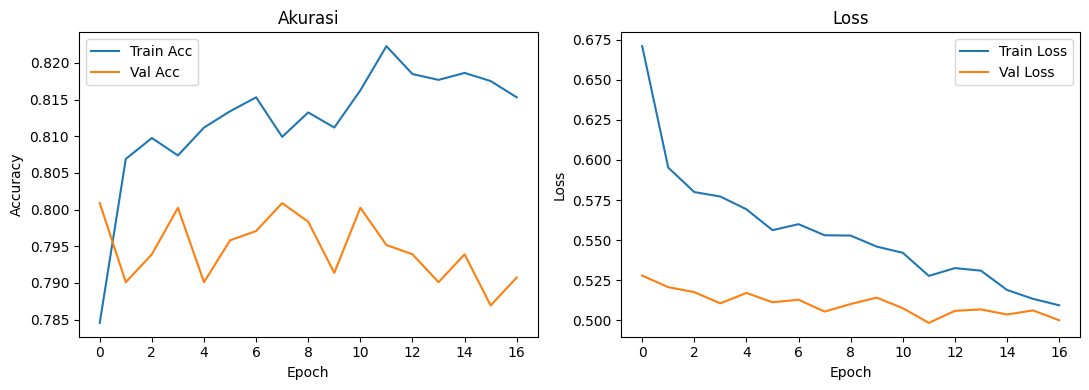

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history.history["accuracy"], label="Train Acc")
ax[0].plot(history.history["val_accuracy"], label="Val Acc")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend(); ax[0].set_title("Akurasi")

ax[1].plot(history.history["loss"], label="Train Loss")
ax[1].plot(history.history["val_loss"], label="Val Loss")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend(); ax[1].set_title("Loss")

plt.tight_layout()
plt.show()

## Langkah 12: Menyimpan Model, Scaler, dan Metadata



In [15]:
EXPORT_DIR = Path("/content/drive/MyDrive/glucosafe/model_export")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Simpan Model (format .h5)
model.save("glucosafe_model.h5")
print("✅ Model berhasil disimpan sebagai: glucosafe_model.h5")

# 2. Simpan Scaler
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
print("✅ Scaler berhasil disimpan sebagai: scaler.pkl")

# 3. Simpan urutan fitur dan label kelas
with open("feature_names.json", "w", encoding="utf-8") as f:
    json.dump({"features": FEATURES, "labels": {str(k): v for k, v in LABELS.items()}}, f, indent=2)
print("✅ feature_names.json tersimpan")

# 4. Simpan versi library (untuk menyamakan requirements.txt di JS15)
meta = {
    "tensorflow": tf.__version__,
    "scikit_learn": sklearn.__version__,
    "python": f"{sys.version_info.major}.{sys.version_info.minor}",
    "test_accuracy": round(float(test_acc), 4),
}
with open("meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)
print("✅ meta.json tersimpan:", meta)

# 5. Salin semua ke Google Drive agar tidak hilang saat sesi Colab berakhir
for name in ["glucosafe_model.h5", "scaler.pkl", "feature_names.json", "meta.json"]:
    shutil.copy(name, EXPORT_DIR / name)
print("\n📁 Semua file disalin ke:", EXPORT_DIR)

✅ Model berhasil disimpan sebagai: glucosafe_model.h5
✅ Scaler berhasil disimpan sebagai: scaler.pkl
✅ feature_names.json tersimpan
✅ meta.json tersimpan: {'tensorflow': '2.21.0', 'scikit_learn': '1.6.1', 'python': '3.13', 'test_accuracy': 0.8093}

📁 Semua file disalin ke: /content/drive/MyDrive/glucosafe/model_export


In [16]:
# (Opsional) Unduh langsung ke komputer
from google.colab import files
for name in ["glucosafe_model.h5", "scaler.pkl", "feature_names.json", "meta.json"]:
    files.download(name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>